<a href="https://colab.research.google.com/github/JuCaRiCo/202602-AnaliticaDescriptivaPredictiva/blob/main/Rivera_JuanCarlos_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** Juan Carlos Rivera Cordova  

**Matrícula:** 271760

**Fecha:** 2026/10/11

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [ ]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación?  | Un Cliente |  
| ¿Qué se predice? | Si el cliente contratará o no un depósito a plazo fijo (y) |
| ¿Qué tipo de problema es? |Clasificación binaria |
| ¿En qué momento se haría la predicción y qué información existiría entonces? | Previo al contacto del cliente. <br/>Existiría la información:<br/> - Demografica/financiera/contexto del cliente (age, job, marital, education, default, housing, loan)<br/>- Historial de campañas previas (pdays, previous, poutcome, contact, month, day_of_week)<br/> - Indicadores macros (emp.var.rate, cons.price.idx, cons.conf.idx, euribor3m, nr.employed) |
| ¿Qué columnas no deberían usarse como características y por qué? | Podrian ser duration e 'y', duration no se conoce previo a la llamada, al igual que y, o no en funcion de la respuesta del cliente |

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito? Investigando, parece ser que la probabilidad de exito esta entre 10% y 15%, por lo que esperariamos algo como 10% a 12%

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas? <br/>

**- Valores NaN**: No espero encontrar muchos valores NaN explícitos, ya que la pista menciona que los datos faltantes en las categóricas se codificaron como el texto 'unknown'.

**- Columnas con 'unknown'**: Esperaría encontrar 'unknown' principalmente en variables categóricas de información personal y financiera sensible del cliente, como job, education, marital, housing y loan, debido a que en llamadas o registros bancarios no siempre se recopilan o comparten todos los datos personales/financieros. Generalmente los clientes actuan con temor de querer proporcionar datos sensibles.

**- Cantidad de filas:** Dado que se trata de datos administrativos y encuestas telefónicas, considero que entre un 10% y un 20% de los registros podrían contener al menos una variable con 'unknown', afectando a unos 4,000 a 8,000 contactos.


In [ ]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

# 1. Dimensiones del conjunto
print("Dimensiones del conjunto: ")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}\n")
print("-"*40)

# 2. Tipo de dato de cada columna
print("Tipo de dato por columna:")
print(df.dtypes, "\n")
print("-"*40)

# 3. Número de valores únicos por columna (ordenado de menor a mayor)
print("Número de valores únicos por columna (ordenado):")
unicos = df.nunique().sort_values(ascending=True)
print(unicos)

Dimensiones del conjunto: 
Filas: 41188
Columnas: 21

----------------------------------------
Tipo de dato por columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object 

----------------------------------------
Número de valores únicos por columna (ordenado):
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education           

In [ ]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

# 1. Total de valores NaN del conjunto,
total_nan = df.isna().sum().sum()
print(f"Total de valores NaN del conjunto: {total_nan}\n")
print("-"*40)

# 2 . Para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
conteo_unknown = (df[categoricas] == "unknown").sum()
conteo_unknown = conteo_unknown[conteo_unknown > 0]
print(f"Filas con 'unknown' por columna:\n{conteo_unknown}")
print("-"*40)

# 3. Conteo como porcentaje de las filas.
porcentaje_unknown = (conteo_unknown / len(df)) * 100
print(f"\nPorcentaje de filas con 'unknown' por columna:\n{porcentaje_unknown}")

Total de valores NaN del conjunto: 0

----------------------------------------
Filas con 'unknown' por columna:
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64
----------------------------------------

Porcentaje de filas con 'unknown' por columna:
job           0.801204
marital       0.194231
education     4.202680
default      20.872584
housing       2.403613
loan          2.403613
dtype: float64


In [ ]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
duplicados_totales = df.duplicated().sum()
print("Conteo de Celdas completamente idénticas: ", duplicados_totales)


Conteo de Celdas completamente idénticas:  12


In [ ]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

# 1. Cuántas filas tienen pdays igual a 999 y qué porcentaje
conteo_pdays_999 = (df["pdays"] == 999).sum()
porcentaje_pdays_999 = conteo_pdays_999 / len(df) * 100
print(f"Filas con pdays = 999: {conteo_pdays_999:,} ({porcentaje_pdays_999:.2f}%)\n")
print("-"*40 + "\n")

# 2. Tabla de contingencia entre poutcome y (previous == 0)
print("Tabla de contingencia: poutcome vs (previous == 0):")
crosstab_previous = pd.crosstab(df["poutcome"], df["previous"] == 0)
print(crosstab_previous)
print("\n" + "-"*40 + "\n")

# 3. Tabla de contingencia entre poutcome y (pdays == 999)
print("Tabla de contingencia: poutcome vs (pdays == 999):")
crosstab_pdays = pd.crosstab(df["poutcome"], df["pdays"] == 999)
print(crosstab_pdays)

Filas con pdays = 999: 39,673 (96.32%)

----------------------------------------

Tabla de contingencia: poutcome vs (previous == 0):
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

----------------------------------------

Tabla de contingencia: poutcome vs (pdays == 999):
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


In [ ]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.

# 1. Edad mínima y máxima
min_age = df["age"].min()
max_age = df["age"].max()
print(f"Rango de edad (age): {min_age} a {max_age} años")
print("-"*40 + "\n")

# 2. Cuantas llamadas con duration igual a 0
duration_cero = (df["duration"] == 0).sum()
print(f"Llamadas con duration == 0: {duration_cero}")
print("-"*40 + "\n")

# 3. Mínimo y máximo de campaign
min_campaign = df["campaign"].min()
max_campaign = df["campaign"].max()
print(f"Rango de la campaña (campaign): {min_campaign} a {max_campaign}")
print("-"*40 + "\n")

# 4. Filas con previous negativo
previous_neg = (df["previous"] < 0).sum()
print(f"Llamadas con previous < 0: {previous_neg}")

Rango de edad (age): 17 a 98 años
----------------------------------------

Llamadas con duration == 0: 4
----------------------------------------

Rango de la campaña (campaign): 1 a 56
----------------------------------------

Llamadas con previous < 0: 0


**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.

**Resumen de problemas de calidad detectados:**
- Valores NaN tradicionales: 0 en todo el conjunto (0.0%).
- Faltantes codificados como 'unknown': Presentes en 6 variables categóricas: default con 8,597 filas (20.87%), education con 1,731 filas (4.20%), housing y loan con 990 filas cada una (2.40%), job con 330 filas (0.80%) y marital con 80 filas (0.19%).
- Duplicados exactos: 12 filas completamente idénticas (0.03%).
- Llamadas con duración cero (duration == 0): 4 filas.
- Valores fuera de rango / incoherencias: No hay valores negativos en previous (mínimo 0) ni edades fuera de rangos (age entre 17 y 98 años).

**Problemas que dependen del significado de la variable:**
- duration = 0 (4 filas): Representa llamadas no concretadas o fallidas inmediatamente; su resultado operativo siempre es y = 'no'.
- pdays == 999: no es un dato atipico erróneo o faltante, sino que es el valor que especial que se usa para determinar que el cliente no ha sido contactado en previas campañas.


**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

Debe mantenerse como una categoria y no eliminarlas.

**Justificación:**
- Dado que el numero de registros con este valor es muy alto (8,597), aproximadamente un 20.8% del total del dataset, la perdida de registros seria masiva.


## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué?
Sí, la proporción va a quedar prácticamente igualita en los dos lados (tanto en el de entrenamiento como en el de prueba). Porque le estamos metiendo la regla de estratificación (stratify=df['y']), lo que esto hace es que no ponga todos los que dijeron 'si' de un solo lado, sino que haga una reparticion pareja.

In [ ]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.

# 1. División estratificada (80% entrenamiento, 20% prueba) con random_state=42
entrenamiento, prueba = train_test_split(
    df,
    test_size=0.20,
    stratify=df["y"],
    random_state=42
)

# 2. Copiando ent y creación de la columna numérica 'suscribe' (1 para yes, 0 para no)
ent = entrenamiento.copy()
ent["suscribe"] = (ent["y"] == "yes").astype(int)

# 3. Imprimir tamaños de entrenamiento y prueba
print("Tamaños de los conjuntos: ")
print(f"Entrenamiento: {entrenamiento.shape[0]} filas ({entrenamiento.shape[0]/len(df):.2%})")
print(f"Prueba: {prueba.shape[0]} filas ({prueba.shape[0]/len(df):.2%})\n")

print("-"*40 + "\n")

# 4. Imprimir porcentaje de contratación en cada uno
pct_ent = (entrenamiento["y"] == "yes").mean() * 100
pct_prueba = (prueba["y"] == "yes").mean() * 100

print("Porcentaje de contratación (y == 'yes'):")
print(f"Entrenamiento: {pct_ent:.2f}%")
print(f"Prueba:        {pct_prueba:.2f}%")



Tamaños de los conjuntos: 
Entrenamiento: 32950 filas (80.00%)
Prueba: 8238 filas (20.00%)

----------------------------------------

Porcentaje de contratación (y == 'yes'):
Entrenamiento: 11.27%
Prueba:        11.26%


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [ ]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.

**Comparación de resultados:**
- Entrenamiento: 32,950 filas (80%), con una tasa de contratación de 11.27%
- Prueba: 8,238 filas (20%), con una tasa de contratación de 11.26%.

**Contraste con la predicción:**

- La prediccion fue sumamente acertada, hubo una ligera variacion que debe ser por algunas unidades de la parte fraccional.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría?
Si el modelo predijera siempre no, obtendria una exactitud de al rededor de 88.73%, esto debido a que el entrenamiento da al rededor de 11.27%  de la clase 'yes'

Número de clientes por clase:
y
no     29238
yes     3712
Name: count, dtype: int64
Porcentaje de clientes por clase:
y
no     88.734446
yes    11.265554
Name: proportion, dtype: float64
----------------------------------------


Razón entre clase mayoritaria ('no') y minoritaria ('yes'): 7.88 a 1
----------------------------------------

Exactitud de responder siempre 'no': 88.73%

----------------------------------------



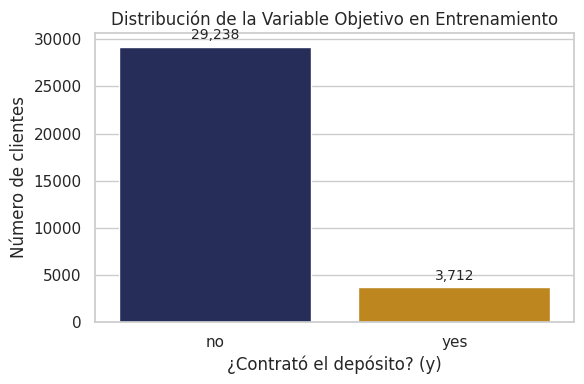

In [ ]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.

# 1. Número y porcentaje de clientes de cada clase en ent
conteo_clases = ent["y"].value_counts()
porcentaje_clases = ent["y"].value_counts(normalize=True) * 100
print("Número de clientes por clase:")
print(conteo_clases)
print("Porcentaje de clientes por clase:")
print(porcentaje_clases)

print("-"*40 + "\n")

# 2. Razón entre la clase mayoritaria y la minoritaria
razon_desbalance = conteo_clases["no"] / conteo_clases["yes"]
print(f"\nRazón entre clase mayoritaria ('no') y minoritaria ('yes'): {razon_desbalance:.2f} a 1")

print("-"*40 + "\n")

# 3. Exactitud de responder siempre "no"
exactitud_no = (ent["y"] == "no").mean() * 100
print(f"Exactitud de responder siempre 'no': {exactitud_no:.2f}%\n")

print("-"*40 + "\n")

# 4. Gráfica de barras con el número de clientes por clase
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=ent, x="y", hue="y", palette=COLORES_CLASE, legend=False)
plt.title("Distribución de la Variable Objetivo en Entrenamiento", fontsize=12)
plt.xlabel("¿Contrató el depósito? (y)")
plt.ylabel("Número de clientes")

# Etiquetas numéricas sobre cada barra
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10, xytext=(0, 3),
                textcoords="offset points")

plt.tight_layout()
plt.show()

**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.

**Hallazgos:**
- Distribución de clases: En el conjunto de entrenamiento de 32,950 observaciones, 29,238 clientes pertenecen a la clase 'no' (88.73%) y 3,712 clientes pertenecen a la clase 'yes' (11.27%).
- Responder siempre 'no' obtiene un nivel de exactitud del 88.73%.

**Comparación con las predicciones:**
- Parte A: La predicción inicial estimaba una conversión de entre 3% y 5%, de acuerdo a investigaciones que realice; el resultado arrojado por el código (11.27%) se ubica exactamente dentro del rango previsto.
- Parte D: La predicción calculó un 88.73% de exactitud para el clasificador trivial, lo cual coincide con la métrica obtenida tras ejecutar la celda.

**Implicaciones para la evaluación del modelo:**
- La metrica de exactitud puede ser engañosa para este problema. Un modelo que prediga 'no' para todos los casos alcanzaría cerca del 89% de aciertos sin haber detectado a un solo cliente interesado en contratar el depósito a plazo.

### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no?
Esperaría que las variables numéricas con mayor diferencia entre quienes contratan ('yes') y quienes no ('no') sean:
- pdays y previous, esto debido a que quienes ya han sido contactados previamente son generalmente mas receptivos.
- duration: Esto debido a que las llamadas más largas suelen correlacionarse con un mayor interés por parte del cliente.

Mediana de variables numéricas por clase de 'y':
y                    no      yes  Diferencia
age               38.00    37.00       -1.00
duration         164.00   448.00      284.00
campaign           2.00     2.00        0.00
pdays            999.00   999.00        0.00
previous           0.00     0.00        0.00
emp.var.rate       1.10    -1.80       -2.90
cons.price.idx    93.92    93.20       -0.72
cons.conf.idx    -41.80   -40.40        1.40
euribor3m          4.86     1.27       -3.59
nr.employed     5195.80  5099.10      -96.70
----------------------------------------



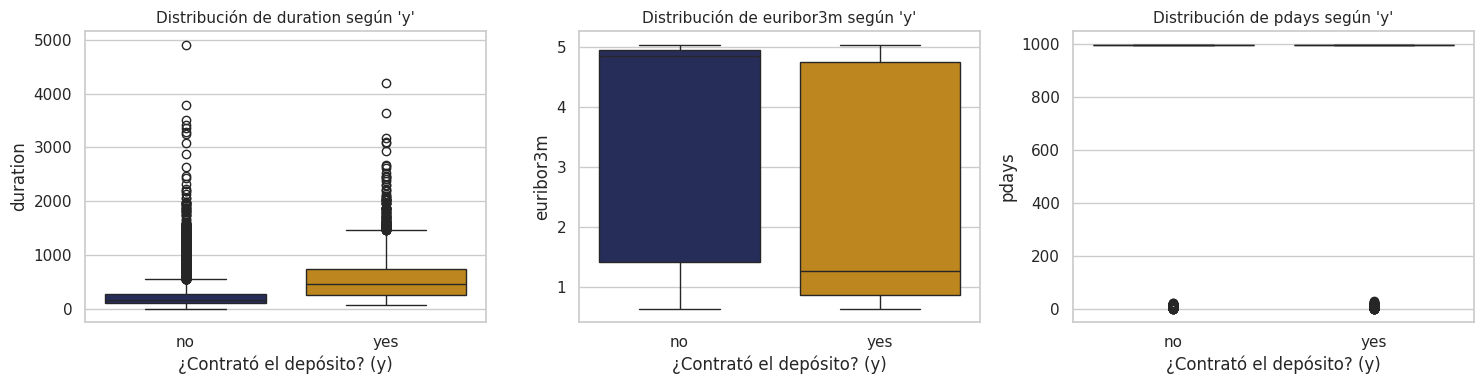

In [ ]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.

# 1. Mediana de cada variable numérica por clase de y, y la trasponemos para mejor claridad
medianas_por_clase = ent.groupby("y")[numericas].median().T

# Agregamos una columna de Diferencia para poder ver la realcion de mejor manera
medianas_por_clase["Diferencia"] = medianas_por_clase["yes"] - medianas_por_clase["no"]

print("Mediana de variables numéricas por clase de 'y':")
print(medianas_por_clase.round(2))

print("-"*40 + "\n")

# 2. Diagramas de caja (boxplots) por clase de 'y' de 3 variables seleccionadas
# Seleccionamos: duration, euribor3m y pdays
vars_boxplot = ["duration", "euribor3m", "pdays"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, var in enumerate(vars_boxplot):
    sns.boxplot(
        data=ent,
        x="y",
        y=var,
        hue="y",
        palette=COLORES_CLASE,
        ax=axes[i],
        legend=False
    )
    axes[i].set_title(f"Distribución de {var} según 'y'", fontsize=11)
    axes[i].set_xlabel("¿Contrató el depósito? (y)")
    axes[i].set_ylabel(var)

plt.tight_layout()
plt.show()

**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.

**Variables que SÍ separan las clases**
- duration: Es la variable con mayor contraste. La mediana para los clientes que contrataron ('yes') es de 448.00 segundos, frente a solo 164.00 segundos para los que dijeron 'no'.
- euribor3m: Muestra una clara separación del entorno económico. La mediana es de 1.27% para la clase 'yes', comparada con 4.86% para la clase 'no'.
- emp.var.rate: Pasa de una mediana de 1.10 en la clase 'no' a un valor negativo de -1.80 en la clase 'yes'.

**Variables que NO separan las clases según la mediana:**
- age: Mediana idéntica/muy cercana entre ambas clases (37.00 años para 'yes' vs. 38.00 años para 'no').
- campaign: Mediana idéntica de 2.00 contactos para ambas clases.
- previous: Mediana de 0.00 contactos prevíos para ambas clases.
- pdays: Mediana en 999.00 días en ambas clases debido a la proporción de clientes no contactados previamente.


### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey?

Esperaría que las variables numéricas con mayor cantidad de registros fuera de los límites de Tukey sean:

- pdays y previous: Debido a la fuerte concentración de datos en valores fijos como 999.
- duration y campaign: Presentan una distribución con sesgo positivo, donde la mayoría de las llamadas duran pocos minutos.

In [ ]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

# Cálculo de límites de Tukey (1.5 * IQR) y conteo de valores atípicos por variable
resultados_tukey = []

for var in numericas:
    q1 = ent[var].quantile(0.25)
    q3 = ent[var].quantile(0.75)
    iqr = q3 - q1

    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    # Conteo de observaciones fuera de los límites
    fuera_limites = ent[(ent[var] < lim_inf) | (ent[var] > lim_sup)]
    cant_atipicos = len(fuera_limites)
    pct_atipicos = (cant_atipicos / len(ent)) * 100

    resultados_tukey.append({
        "Variable": var,
        "Límite Inferior": round(lim_inf, 2),
        "Límite Superior": round(lim_sup, 2),
        "Atípicos (N)": cant_atipicos,
        "Atípicos (%)": round(pct_atipicos, 2)
    })

df_tukey = pd.DataFrame(resultados_tukey).sort_values(by="Atípicos (N)", ascending=False)

print("--- Valores atípicos según los límites de Tukey (1.5 * IQR) ---")
print(df_tukey.to_string(index=False))

--- Valores atípicos según los límites de Tukey (1.5 * IQR) ---
      Variable  Límite Inferior  Límite Superior  Atípicos (N)  Atípicos (%)
      previous             0.00             0.00          4534         13.76
      duration          -221.00           643.00          2366          7.18
      campaign            -2.00             6.00          1916          5.81
         pdays           999.00           999.00          1226          3.72
           age             9.50            69.50           368          1.12
 cons.conf.idx           -52.15           -26.95           359          1.09
  emp.var.rate            -6.60             6.20             0          0.00
cons.price.idx            91.70            95.37             0          0.00
     euribor3m            -4.08            10.39             0          0.00
   nr.employed          4905.60          5421.60             0          0.00


**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado.
No, no los eliminaría, la justificacion a continuación:
- pdays y previous: Los valores fuera del rango de Tukey en estas variables representan a los clientes que sí han sido contactados previamente en campañas pasadas. Aunque estadísticamente son atípicos, funcionalmente son la población de mayor valor predictivo y mayor tasa de conversión. Eliminar estas filas destruiría la señal más fuerte del modelo.
- duration: Las llamadas de larga duración generan valores atípicos porque la mayoría de las interacciones duran muy poco. Sin embargo, estas duraciones altas reflejan interacciones reales donde el cliente mostró interés genuino en el producto
- campaign: Valores altos en esta variable representan clientes que recibieron múltiples llamadas en la campaña actual. Aunque un número elevado de llamadas puede indicar insistencia o resistencia del cliente, son posibles registros de operaciones de telemarketing.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`?

Considero que la transformación logarítmica (np.log1p) reducirá más la asimetría de la variable campaign que la raíz cuadrada (np.sqrt). La variable campaign presenta una asimetría positiva pronunciada hacia la derecha (con un mínimo de 1 contacto y un máximo de hasta 56 contactos).La transformación logarítmica comprime los valores altos de forma mucho más agresiva y cóncava que la función de raíz cuadrada.

Comparativa de Asimetría: 
          original  raiz_cuadrada  logaritmo
age           0.76           0.43       0.13
duration      3.33           1.20      -0.43
campaign      4.74           2.16       1.35

--------------------------------------------------



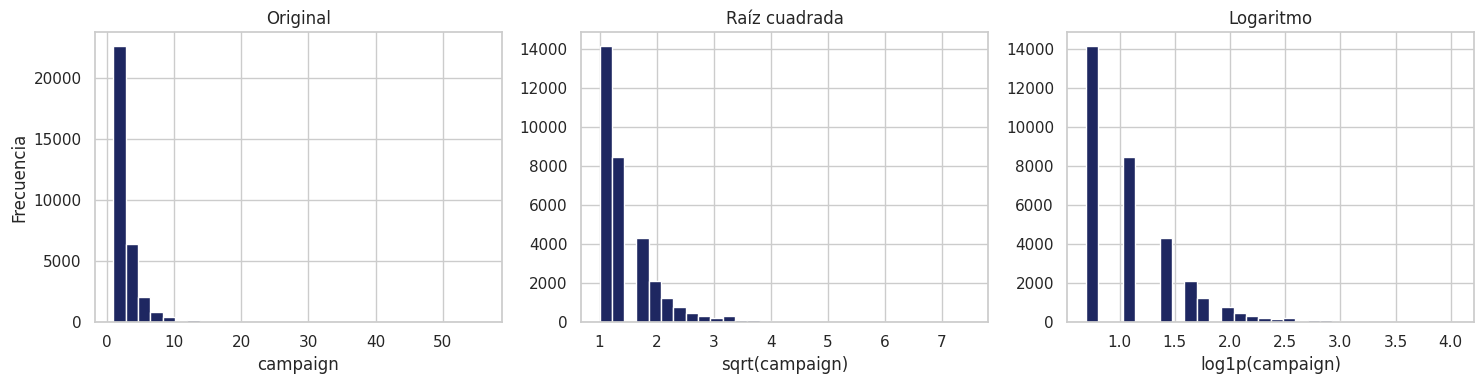

In [ ]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.

# 1. Tabla comparativa de asimetría para age, duration y campaign
variables_asimetria = ["age", "duration", "campaign"]

filas_comparacion = []
for var in variables_asimetria:
    filas_comparacion.append({
        "original": ent[var].skew(),
        "raiz_cuadrada": np.sqrt(ent[var]).skew(),
        "logaritmo": np.log1p(ent[var]).skew()
    })

comparacion = pd.DataFrame(filas_comparacion, index=variables_asimetria).round(2)
print("Comparativa de Asimetría: ")
print(comparacion)
print("\n" + "-"*50 + "\n")

# 2. Histogramas de 'campaign' (Original, Raíz cuadrada, Logaritmo)
variable = "campaign"

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))

ejes[0].hist(ent[variable].dropna(), bins=30, color=AZUL, edgecolor="white")
ejes[0].set_title("Original")
ejes[0].set_xlabel("campaign")
ejes[0].set_ylabel("Frecuencia")

ejes[1].hist(np.sqrt(ent[variable]).dropna(), bins=30, color=AZUL, edgecolor="white")
ejes[1].set_title("Raíz cuadrada")
ejes[1].set_xlabel("sqrt(campaign)")

ejes[2].hist(np.log1p(ent[variable]).dropna(), bins=30, color=AZUL, edgecolor="white")
ejes[2].set_title("Logaritmo")
ejes[2].set_xlabel("log1p(campaign)")

plt.tight_layout()
plt.show()

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable. Escribe tu respuesta aquí y compárala con tu predicción.

**Reporte de asimetrías:**
- age: Asimetría original de 0.76. Con raíz cuadrada disminuye a 0.43 y con logaritmo (log1p) baja a 0.13.
- duration: Asimetría original alta de 3.33. Con raíz cuadrada se reduce a 1.20 y con logaritmo pasa a -0.43.
- campaign: Asimetría original de 4.74. Con raíz cuadrada baja a 2.16 y con logaritmo (log1p) se reduce a 1.35.

**Decisión sobre transformaciones:**
- campaign: Se aplicaría la transformación logarítmica (log1p) para modelos sensibles a la escala, ya que disminuye drásticamente la asimetría de 4.74 a 1.35.
- duration: Aunque el logaritmo la lleva a -0.43, no se transformará ni se utilizará en el modelado por tratarse de una variable que produce fuga de información.
- age: Se mantiene en su forma original dado que su asimetría inicial (0.76) es relativamente leve.

**Comparación con la predicción:**
- La predicción acertó: el logaritmo fue más efectivo que la raíz cuadrada para comprimir la cola derecha de campaign, reduciendo la asimetría a 1.35 frente a 2.16 de la raíz cuadrada.



## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases?

**Variable con mayor tasa de contratación por categoría:** Esperaría que sea poutcome (el resultado de la campaña de marketing previa). En particular, los clientes etiquetados con la categoría 'success' deberían registrar la tasa de conversión/contratación más alta del conjunto.

**Variables que casi no separarán las clases:** Esperaría que las variables de servicio de crédito inmediato como housing (préstamo hipotecario) y loan (préstamo personal) muestren tasas de contratación muy similares a la media global en todas sus categorías, aportando poca separación entre clientes que contratan y clientes que no.

In [ ]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.

# 1. Número de categorías únicas por variable categórica en ent
num_categorias = ent[categoricas].nunique().reset_index()
num_categorias.columns = ["Variable", "Número de Categorías"]

print("Número de categorías por variable categórica: ")
print(num_categorias.to_string(index=False))
print("\n" + "-"*50 + "\n")

# 2. Tasa global de contratación en el conjunto ent
tasa_global = ent["suscribe"].mean() * 100
print(f"Tasa global de contratación en entrenamiento (ent): {tasa_global:.2f}%")

Número de categorías por variable categórica: 
   Variable  Número de Categorías
        job                    12
    marital                     4
  education                     8
    default                     3
    housing                     3
       loan                     3
    contact                     2
      month                    10
day_of_week                     5
   poutcome                     3

--------------------------------------------------

Tasa global de contratación en entrenamiento (ent): 11.27%


In [ ]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.

# 1. Transformación a formato largo y cálculo de tasas
formato_largo = (
    ent[categoricas]
    .astype(str)
    .assign(suscribe=ent["suscribe"])
    .melt(id_vars="suscribe", var_name="caracteristica", value_name="categoria")
)

tasas = formato_largo.groupby(["caracteristica", "categoria"])["suscribe"].agg(
    clientes="count", tasa_contratacion="mean"
)

tasas["tasa_contratacion"] = (tasas["tasa_contratacion"] * 100).round(1)

# 2. Muestra de los resultados
print("Categorías con mayor tasa de contratación:")
print(tasas.sort_values("tasa_contratacion", ascending=False).head(12))
print()

print("Categorías con menor tasa de contratación:")
print(tasas.sort_values("tasa_contratacion", ascending=True).head(8))
print()

print("Tablas de default, housing, loan y day_of_week:")
for var in ["default", "housing", "loan", "day_of_week"]:
    print(f"\nTasa de contratación según {var}:")
    print(tasas.loc[var])

Categorías con mayor tasa de contratación:
                           clientes  tasa_contratacion
caracteristica categoria                              
poutcome       success         1105               64.9
month          dec              143               50.3
               mar              436               49.8
               sep              464               44.6
               oct              587               43.3
job            student          711               30.5
               retired         1366               25.5
month          apr             2085               20.5
education      illiterate        16               18.8
marital        unknown           65               16.9
education      unknown         1397               14.8
contact        cellular       20908               14.7

Categorías con menor tasa de contratación:
                            clientes  tasa_contratacion
caracteristica categoria                               
default        yes             

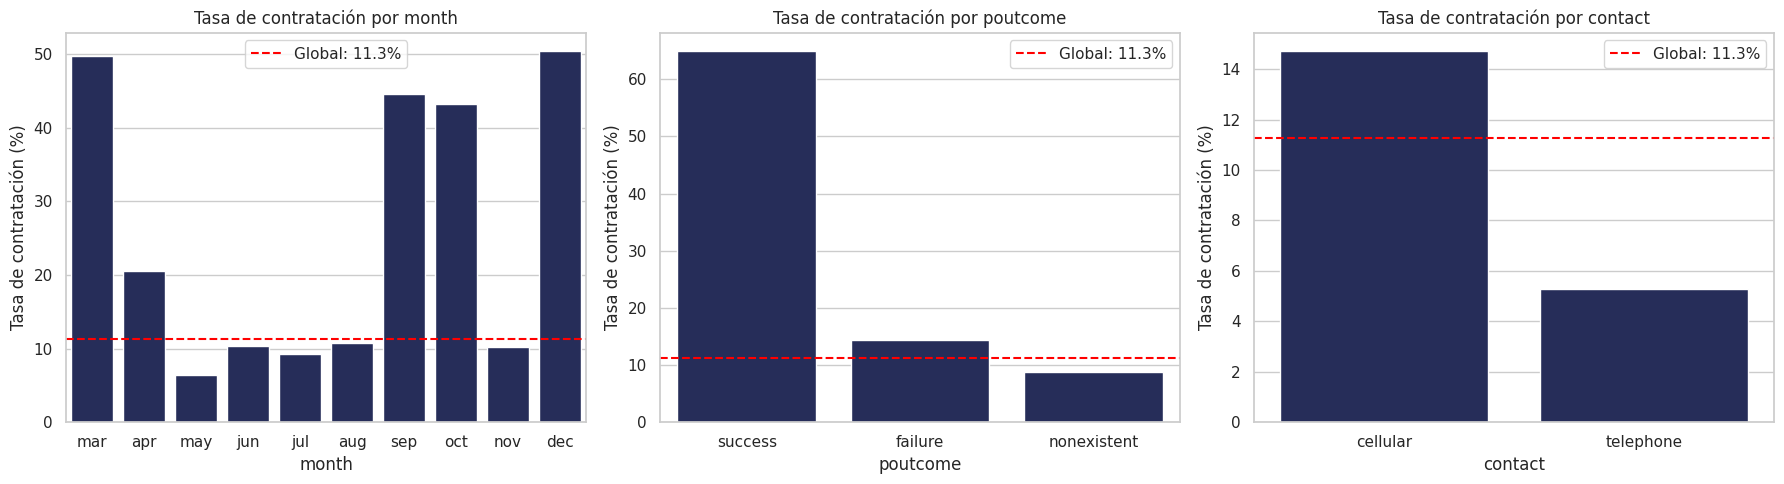

In [ ]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

# Definición del orden cronológico para los meses disponibles en el dataset
orden_meses = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]

# Tasa global
tasa_global_pct = ent["suscribe"].mean() * 100

# Variables a graficar
variables_e3 = ["month", "poutcome", "contact"]

fig, ejes = plt.subplots(1, 3, figsize=(18, 5))

for i, var in enumerate(variables_e3):
    # Calcular tasa de contratación (%) por categoría
    tabla_var = (
        ent.groupby(var)["suscribe"]
        .mean()
        .mul(100)
        .reset_index()
    )

    # Ordenar específicamente para el caso de 'month'
    if var == "month":
        tabla_var[var] = pd.Categorical(tabla_var[var], categories=orden_meses, ordered=True)
        tabla_var = tabla_var.sort_values(var)
    else:
        tabla_var = tabla_var.sort_values(by="suscribe", ascending=False)

    # Gráfica de barras
    sns.barplot(
        data=tabla_var,
        x=var,
        y="suscribe",
        color=AZUL,
        ax=ejes[i]
    )

    # Línea horizontal para la tasa global
    ejes[i].axhline(tasa_global_pct, color="red", linestyle="--", linewidth=1.5, label=f"Global: {tasa_global_pct:.1f}%")

    ejes[i].set_title(f"Tasa de contratación por {var}", fontsize=12)
    ejes[i].set_xlabel(var)
    ejes[i].set_ylabel("Tasa de contratación (%)")
    ejes[i].legend()

plt.tight_layout()
plt.show()

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases.

**Categorías con MAYOR tasa de contratación:**
- poutcome = success: Tasa del 64.9% (N = 1,105 clientes)
- Meses atípicos de alta conversión (month):
  - dec con 50.3% (N = 143)
  - mar con 49.8% (N = 436)
  - sep con 44.6% (N = 464)
  - oct con 43.3% (N = 587).  

**Categorías con MENOR tasa de contratación:**
- default = yes: Tasa del 0.0% (N = 3 clientes).
- default = unknown: Tasa del 5.2% (N = 6,940 clientes).
- contact = telephone: Tasa del 5.3% (N = 12,042 clientes).
- month = may: Tasa del 6.3% (N = 11,011 clientes).
- Perfiles con menor conversión:
  - job = blue-collar con 6.9% (N = 7,441)
  - education = basic.9y con 7.6% (N = 4,826).

**Variables que casi NO separan las clases:**
- housing y loan: Sus categorías presentan tasas muy cercanas a la tasa global (11.3%). En housing, no tiene 10.9% y yes 11.6%. En loan, no tiene 11.3% y yes 11.2%.
- day_of_week: Oscila marginalmente entre 10.2% (mon) y 12.0% (thu).


**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`?

**Significado de unknown en default:**
- El hecho de que la categoría unknown tenga una tasa de contratación (5.2%) considerablemente menor que no (12.9%) indica que la falta de información crediticia no es aleatoria. La etiqueta unknown actúa en sí misma como una señal informativa valiosa para el modelo.

**Cuidado metodológico con las categorías default = yes y education = illiterate:**
- Hay que cuidar la baja representatividad/tamaño de muestra (N muy pequeño).
- En default = yes solo existen 3 clientes en todo el conjunto de entrenamiento (tasa 0.0%), y en education = illiterate solo existen 16 clientes (tasa 18.8%).

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados? Escribe tu respuesta aquí, antes de ejecutar la celda de código.

Esperaría que las correlaciones más altas ocurran entre los siguientes pares de indicadores macroeconómicos (lista macro):

- euribor3m y emp.var.rate: La tasa Euribor a 3 meses y la tasa de variación del empleo suelen estar fuertemente correlacionadas de forma positiva, ya que ambas responden de manera directa a las fases de expansión o contracción del ciclo económico.

- euribor3m y nr.employed: El número de empleados en el mercado laboral tiende a moverse en la misma dirección que las tasas de interés interbancarias de referencia fijadas durante periodos de estabilidad o crecimiento económico.

- emp.var.rate y nr.employed: Miden aspectos estrechamente vinculados de la dinámica laboral, por lo que mantendrán una relación lineal.

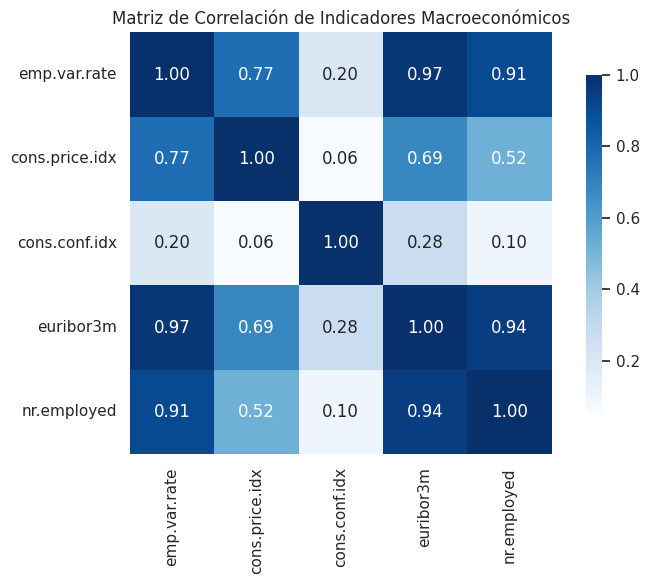

In [25]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

# 1. Matriz de correlación de las variables macroeconómicas
matriz_corr_macro = ent[macro].corr()

# 2. Mapa de calor (heatmap) con anotaciones
plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_corr_macro,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    square=True,
    cbar_kws={"shrink": 0.8}
)

plt.title("Matriz de Correlación de Indicadores Macroeconómicos", fontsize=12)
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican. Escribe tu respuesta aquí y compárala con tu predicción.

**Pares más correlacionados:**
- emp.var.rate y euribor3m: Muestran una correlación casi perfecta de 0.97.
- euribor3m y nr.employed: Presentan una correlación muy fuerte de 0.94.
- emp.var.rate y nr.employed: Registran una correlación de 0.91.
- emp.var.rate y cons.price.idx: Presenta una correlación moderada-alta de 0.77.

**Decisión que implican:**
- Existe una alta multicolinealidad entre las variables macroeconómicas (emp.var.rate, euribor3m y nr.employed).

**Comparación con la predicción:**
- La predicción fue acertada al identificar que las correlaciones más fuertes se darían precisamente entre el trío emp.var.rate, euribor3m y nr.employed, con valores que superan el 0.90 en la matriz de correlación.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [26]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

# Resumen estadístico (describe) de duration agrupado por las clases de la variable objetivo 'y'
resumen_duration = ent.groupby("y")["duration"].describe().round(2)

print("Resumen estadístico de 'duration' por clase de 'y':")
print(resumen_duration)

Resumen estadístico de 'duration' por clase de 'y':
       count    mean     std   min    25%    50%    75%     max
y                                                              
no   29238.0  221.15  208.30   0.0   95.0  164.0  279.0  4918.0
yes   3712.0  549.40  397.49  63.0  252.0  448.0  737.0  4199.0


**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado. Escribe tu respuesta aquí.

**No, no la incluiría.**
- Justificación operacional: Por definición, la variable duration representa la duración de la llamada telefónica en segundos. Cuando el modelo se utiliza en la práctica para seleccionar a qué clientes contactar, esa información no existe, ya que la llamada aún no se ha realizado.
- Justificación con lo observado:
  - Para los clientes que no contrataron (y = 'no'), la media es de 221.15 segundos y la mediana (50%) es de 164.0 segundos.
  - Para los clientes que sí contrataron (y = 'yes'), la media se eleva a 549.40 segundos y la mediana (50%) sube a 448.0 segundos.
  - Esto nos puede traer un gran problema, dado que el modelo se basaría en información del "futuro" y fallaría al desplegarse en producción por no disponer de este dato antes del contacto.


**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras?

- Implica un riesgo de sobreestimación del rendimiento, al realizar una partición aleatoria, observaciones pertenecientes a los mismos periodos temporales y condiciones macroeconómicas se mezclan entre el conjunto de entrenamiento y el de prueba. El modelo "memorizará" las condiciones económicas específicas de esos meses presentes en ambos subconjuntos. Cuando el modelo se aplique a clientes en periodos futuros donde el entorno económico haya cambiado, su desempeño real será sensiblemente inferior al estimado en la validación.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
|La variable duration presenta una gran diferencia entre clases (media en y='yes' de 549.40 s vs. 221.15 s en y='no'), pero no se conoce antes de realizar la llamada. |Eliminar la variable duration de las características del modelo para evitar fuga de información (data leakage) | Preprocesamiento |
|Alta correlación entre indicadores macroeconómicos: emp.var.rate y euribor3m (0.97), euribor3m y nr.employed (0.94), y emp.var.rate y nr.employed |Seleccionar únicamente euribor3m |Preprocesamiento |
|La variable campaign presenta una asimetría pronunciada de 4.74, la cual disminuye a 1.35 al aplicar logaritmo |Aplicar transformación logarítmica (np.log1p) a campaign |Preprocesamiento |
|La categoría default = 'unknown' tiene 6,940 clientes (21% de la muestra) y una tasa de contratación de solo 5.2% (frente al 12.9% de no). |Conservar y tratar 'unknown' como una categoría explícita e informativa en lugar de descartarla. | Preprocesamiento |
|La tasa global de contratación en entrenamiento es de solo 11.3% (y='yes' representa 3,712 de 32,950 observaciones) |Evitar el uso de la exactitud como métrica principal, ya que un modelo ingenuo que prediga siempre 'no' tendría un 88.7% de acierto sin identificar a ningún cliente potencial. |Evaluación |
|Las categorías default = 'yes' (3 clientes) y education = 'illiterate' (16 clientes) tienen un tamaño de muestra extremadamente pequeño. |Agrupar estas categorías raras para evitar alta varianza y sobreajuste |Preprocesamiento |
|La categoría poutcome = 'success' alcanza una tasa de contratación del 64.9% (1,105 clientes), y el canal cellular (14.7%) supera a telephone (5.3%) |Priorizar estas características en la codificación como predictores clave de conversión. |Preprocesamiento|

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio.

- Con el conjunto total: Únicamente las fases iniciales de inspección general, limpieza básica y la división de los datos (Partes A, B y C1).
- Solo con el conjunto de entrenamiento (ent): Toda la exploración analítica profunda (EDA), la transformación de características, el análisis de asimetría (D4), la exploración categórica con cálculo de tasas (E1, E2, E3) y el análisis de correlación entre variables macroeconómicas y duration (F1, F2).
- Criterio: Se debe aislar completamente el conjunto de prueba (test) durante la fase exploratoria para evitar el fuga de datos en la evaluación . El conjunto de prueba debe comportarse estrictamente como "datos no vistos del futuro". Cualquier decisión de preprocesamiento, umbral o transformación debe aprenderse únicamente a partir de los datos de entrenamiento (ent) para garantizar una evaluación justa y no sesgada.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final?

- Decisión sesgada: La selección de transformaciones numéricas como la transformación logarítmica np.log1p en campaign según su skewness, o la decisión de consolidación/codificación de categorías como el tratamiento de default = 'unknown'.
- Cómo se reflejaría en la evaluación final: Al ajustar o tomar decisiones sobre las variables observando también los datos de prueba, se estaría optimizando indirectamente la canalización para que funcione de manera "ideal" sobre ese conjunto particular. En la evaluación final, el modelo parecería tener un desempeño excelente, pero al desplegarlo en un entorno de producción real frente a campañas futuras con nuevos datos, la métrica de rendimiento caería sensiblemente.